# Choosing a financial clock

Each market record contains a time, price, and volume, and their product is its dollar value:

$$
(t_i,p_i,v_i)_{i=1}^{n},\qquad d_i=p_iv_i.
$$

Here, $i$ labels a record; $n$ is the number of records; $t_i$ is time; $p_i$ is price; $v_i$ is traded volume. $d_i=p_iv_i$ is the dollar value assigned to record $i.$

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import hashlib
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=10080)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.data.structures.standard_bars import StandardBars
from RiskLabAI.data.structures.time_bars import TimeBars
from RiskLabAI.utils.constants import CUMULATIVE_DOLLAR, CUMULATIVE_TICKS, CUMULATIVE_VOLUME

FIGURES = ROOT / "outputs" / "figures" / "05_event_based_financial_time"
TABLES = ROOT / "outputs" / "tables" / "05_event_based_financial_time"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {
    "background": "#FFFFFF",
    "axes": "#FFFFFF",
    "text": "#1B365D",
    "cyan": "#0072B2",
    "amber": "#C76D00",
    "green": "#00866A",
    "rose": "#B83B3B",
    "violet": "#A03A78",
    "grid": "#D9DEE5",
}
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 11.5,
    "figure.facecolor": palette["background"],
    "axes.facecolor": palette["axes"],
    "axes.edgecolor": palette["text"],
    "axes.labelcolor": palette["text"],
    "axes.titlecolor": palette["text"],
    "xtick.color": palette["text"],
    "ytick.color": palette["text"],
    "text.color": palette["text"],
    "grid.color": palette["grid"],
    "grid.linestyle": ":",
    "legend.facecolor": palette["axes"],
    "legend.edgecolor": palette["grid"],
    "savefig.facecolor": palette["background"],
})

BAR_COLUMNS = [
    "Time", "Last record", "Open", "High", "Low", "Close",
    "Volume", "Buy volume", "Sell volume", "Records", "Dollar value", "Rule level",
]

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def bar_frame(rows):
    frame = pd.DataFrame(rows, columns=BAR_COLUMNS)
    if not frame.empty:
        frame["Time"] = pd.to_datetime(frame["Time"])
    return frame

raw = raw.sort_values("time").dropna(subset=["time", "close", "volume"]).reset_index(drop=True)
observations = list(raw[["time", "close", "volume"]].itertuples(index=False, name=None))
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Four Ways to Measure Progress

A tick bar ends after a chosen number of records, while a volume bar ends when accumulated volume first reaches its threshold:

$$
\tau_k^{\mathrm{tick}}=\inf\left\{n>\tau_{k-1}:n-\tau_{k-1}\geq h_N\right\},\quad
\tau_k^{\mathrm{volume}}=\inf\left\{n>\tau_{k-1}:\sum_{i=\tau_{k-1}+1}^{n}v_i\geq h_V\right\},
$$

Here, $\tau_k$ is the ending record of bar $k$; $\tau_{k-1}$ is the preceding ending record; $n$ is a candidate ending record. $h_N$ is the required record count; $v_i$ is volume in record $i$; $h_V$ is the volume threshold; $\inf$ selects the first qualifying record.

A dollar bar ends when accumulated price times volume first reaches a chosen dollar threshold:

$$
\tau_k^{\mathrm{dollar}}=\inf\left\{n>\tau_{k-1}:\sum_{i=\tau_{k-1}+1}^{n}p_iv_i\geq h_D\right\}.
$$

Here, $\tau_k^{\mathrm{dollar}}$ is the ending record of dollar bar $k$; $\tau_{k-1}$ is the previous ending record. $n$ is a candidate ending record; $p_i$ is price; $v_i$ is volume; $h_D$ is the dollar threshold; $\inf$ selects the first crossing.

In [2]:
target_bars = 336
tick_level = len(raw) / target_bars
volume_level = raw["volume"].sum() / target_bars
dollar_level = (raw["close"] * raw["volume"]).sum() / target_bars

bars = {
    "Clock time": bar_frame(TimeBars("MIN", 30).construct_bars_from_data(observations)),
    "Tick time": bar_frame(StandardBars(CUMULATIVE_TICKS, tick_level).construct_bars_from_data(observations)),
    "Volume time": bar_frame(StandardBars(CUMULATIVE_VOLUME, volume_level).construct_bars_from_data(observations)),
    "Dollar time": bar_frame(StandardBars(CUMULATIVE_DOLLAR, dollar_level).construct_bars_from_data(observations)),
}

provenance = pd.DataFrame({
    "Item": ["Provider", "Archive", "Public access", "Market", "First record", "Last record", "Records used", "Basic record", "Archive SHA256"],
    "Value": [
        "Binance Data Vision",
        "BTCUSDT-1m-2021-01.zip",
        "Direct public download",
        "Bitcoin quoted in USDT",
        raw["time"].iloc[0].isoformat(),
        raw["time"].iloc[-1].isoformat(),
        f"{len(raw):,}",
        "One-minute spot interval",
        data_hash,
    ],
})
save_table(provenance, "data_provenance", "Source and limits of the public Binance illustration.", "tab:chapter4-data-provenance")
display(provenance)

,Item,Value
0,Provider,Binance Data Vision
1,Archive,BTCUSDT-1m-2021-1zip
2,Public access,Direct public download
3,Market,Bitcoin quoted in USDT
4,First record,2021-01-01T00:00:00
5,Last record,2021-01-07T23:59:00
6,Records used,"10,080"
7,Basic record,One-minute spot interval
8,Archive SHA256,9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A2...


In [3]:
levels = {
    "Clock time": "30 minutes",
    "Tick time": f"{tick_level:.0f} records",
    "Volume time": f"{volume_level:,.3f} BTC",
    "Dollar time": f"USDT {dollar_level:,.2f}",
}
summary_rows = []
start_time = raw["time"].iloc[0] - pd.Timedelta(minutes=1)
for name, frame in bars.items():
    previous_times = pd.Series([start_time, *frame["Time"].iloc[:-1].tolist()])
    duration = (frame["Time"].reset_index(drop=True) - previous_times).dt.total_seconds() / 60.0
    if name == "Tick time":
        excess = (frame["Records"] - tick_level) / tick_level
    elif name == "Volume time":
        excess = (frame["Volume"] - volume_level) / volume_level
    elif name == "Dollar time":
        excess = (frame["Dollar value"] - dollar_level) / dollar_level
    else:
        excess = pd.Series(np.zeros(len(frame)))
    summary_rows.append({
        "Measure of progress": name,
        "Rule": levels[name],
        "Complete bars": len(frame),
        "Median records": frame["Records"].median(),
        "Median minutes": duration.median(),
        "Mean excess over rule (%)": 100.0 * excess.mean(),
    })
standard_bar_summary = pd.DataFrame(summary_rows)
save_table(standard_bar_summary, "standard_bar_summary", "Four bar rules applied to the same 10,080 one-minute records.", "tab:standard-bar-summary")
display(standard_bar_summary.round(4))

,Measure of progress,Rule,Complete bars,Median records,Median minutes,Mean excess over rule (%)
0,Clock time,30 minutes,335,30,30,0
1,Tick time,30 records,336,30,30,0
2,Volume time,"2,446.575 BTC",325,28,28,3.1648
3,Dollar time,"USDT 81,498,376.55",324,28,28,3.4932


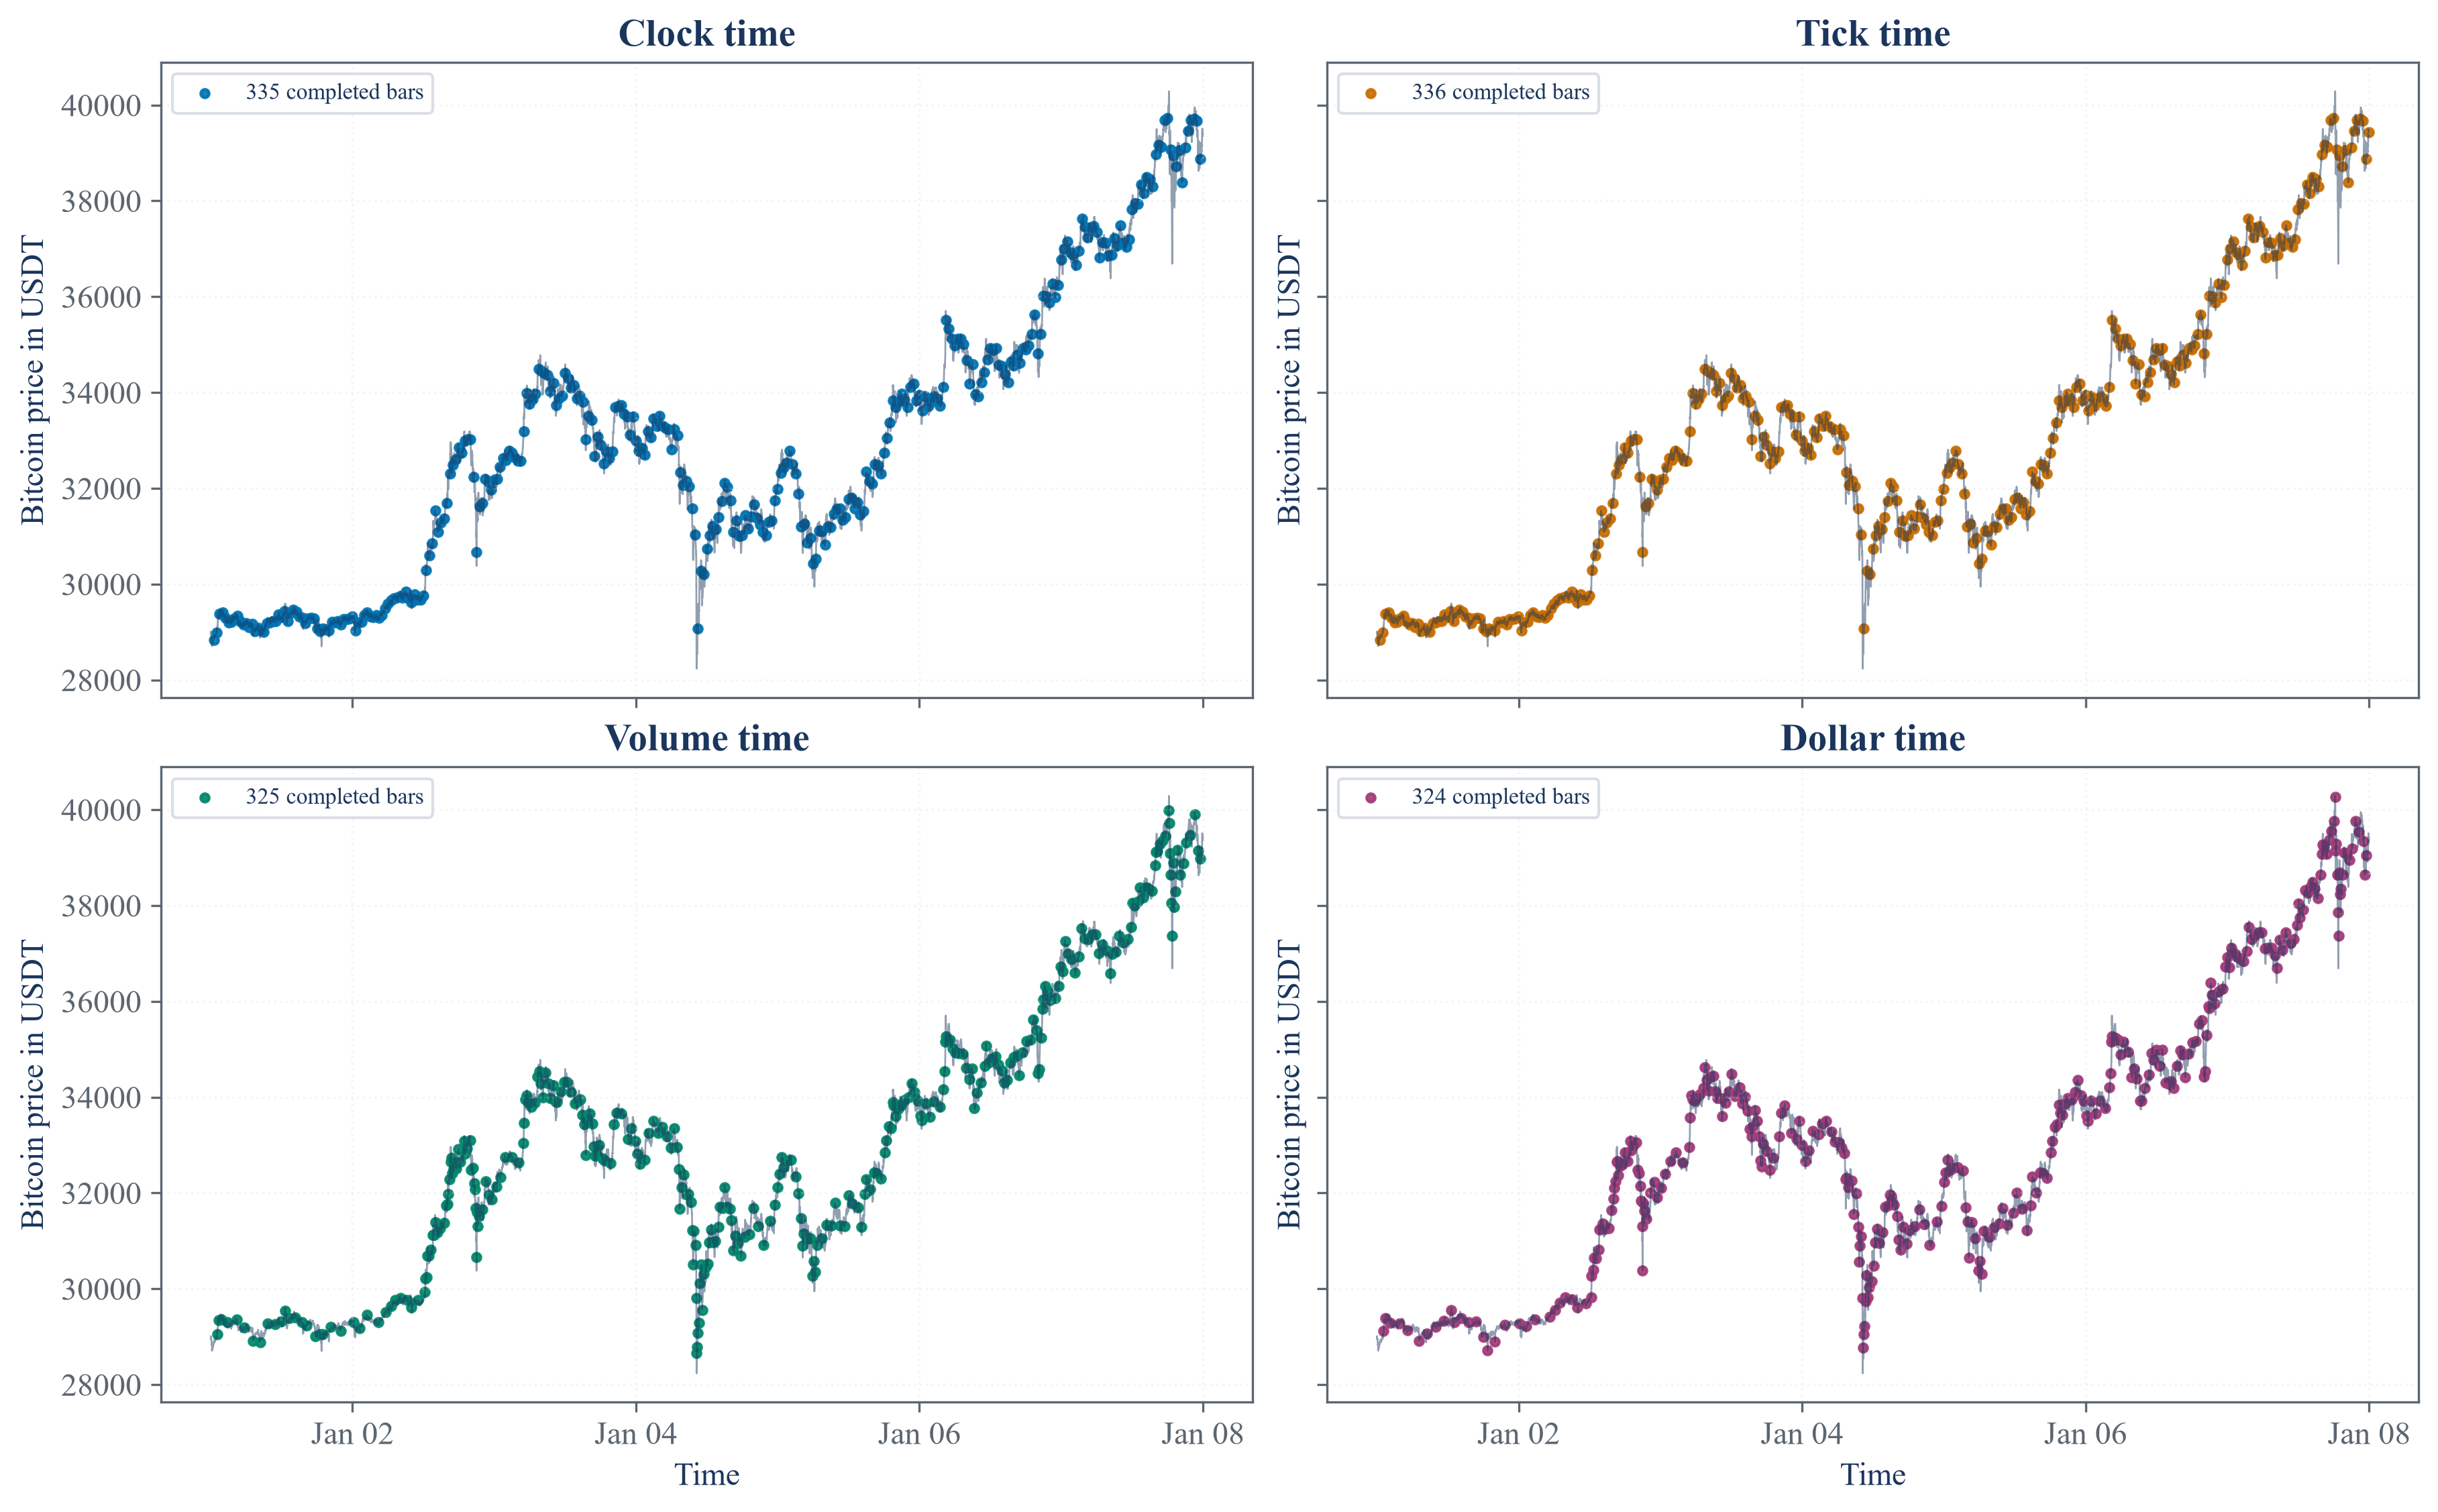

In [4]:
colors = [palette["cyan"], palette["amber"], palette["green"], palette["violet"]]
figure, axes = plt.subplots(2, 2, figsize=(12.0, 7.4), sharex=True, sharey=True, constrained_layout=True)
for axis, (name, frame), color in zip(axes.ravel(), bars.items(), colors):
    axis.plot(raw["time"], raw["close"], color=palette["text"], alpha=0.48, linewidth=0.65)
    axis.scatter(frame["Time"], frame["Close"], color=color, s=9, alpha=0.90, label=f"{len(frame)} completed bars")
    axis.set_title(name)
    axis.set_ylabel("Bitcoin price in USDT")
    axis.grid(True, alpha=0.28)
    axis.legend(fontsize=8.2, loc="upper left")
for axis in axes[-1, :]:
    axis.set_xlabel("Time")
    axis.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
figure.savefig(FIGURES / "four_financial_clocks.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "four_financial_clocks.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "four_financial_clocks.png")))
plt.close(figure)

## Unequal Activity

A completed bar may pass its threshold, but the excess is smaller than the final record that caused the crossing:

$$
0\leq \sum_{i=\tau_{k-1}+1}^{\tau_k}v_i-h_V<v_{\tau_k},\qquad
0\leq \sum_{i=\tau_{k-1}+1}^{\tau_k}p_iv_i-h_D<p_{\tau_k}v_{\tau_k}.
$$

Here, $k$ labels the bar; $\tau_{k-1}+1$ and $\tau_k$ are its first and last records; $v_i$ is volume; $p_i$ is price. $h_V$ is the volume threshold; $h_D$ is the dollar threshold; $v_{\tau_k}$ and $p_{\tau_k}v_{\tau_k}$ are the final volume and dollar contributions.

,Measure of progress,Smallest record count,Middle record count,Largest record count,Standard deviation divided by mean
0,Clock time,30,30,30,0
1,Tick time,30,30,30,0
2,Volume time,3,28,129,0.6132
3,Dollar time,4,28,150,0.6627


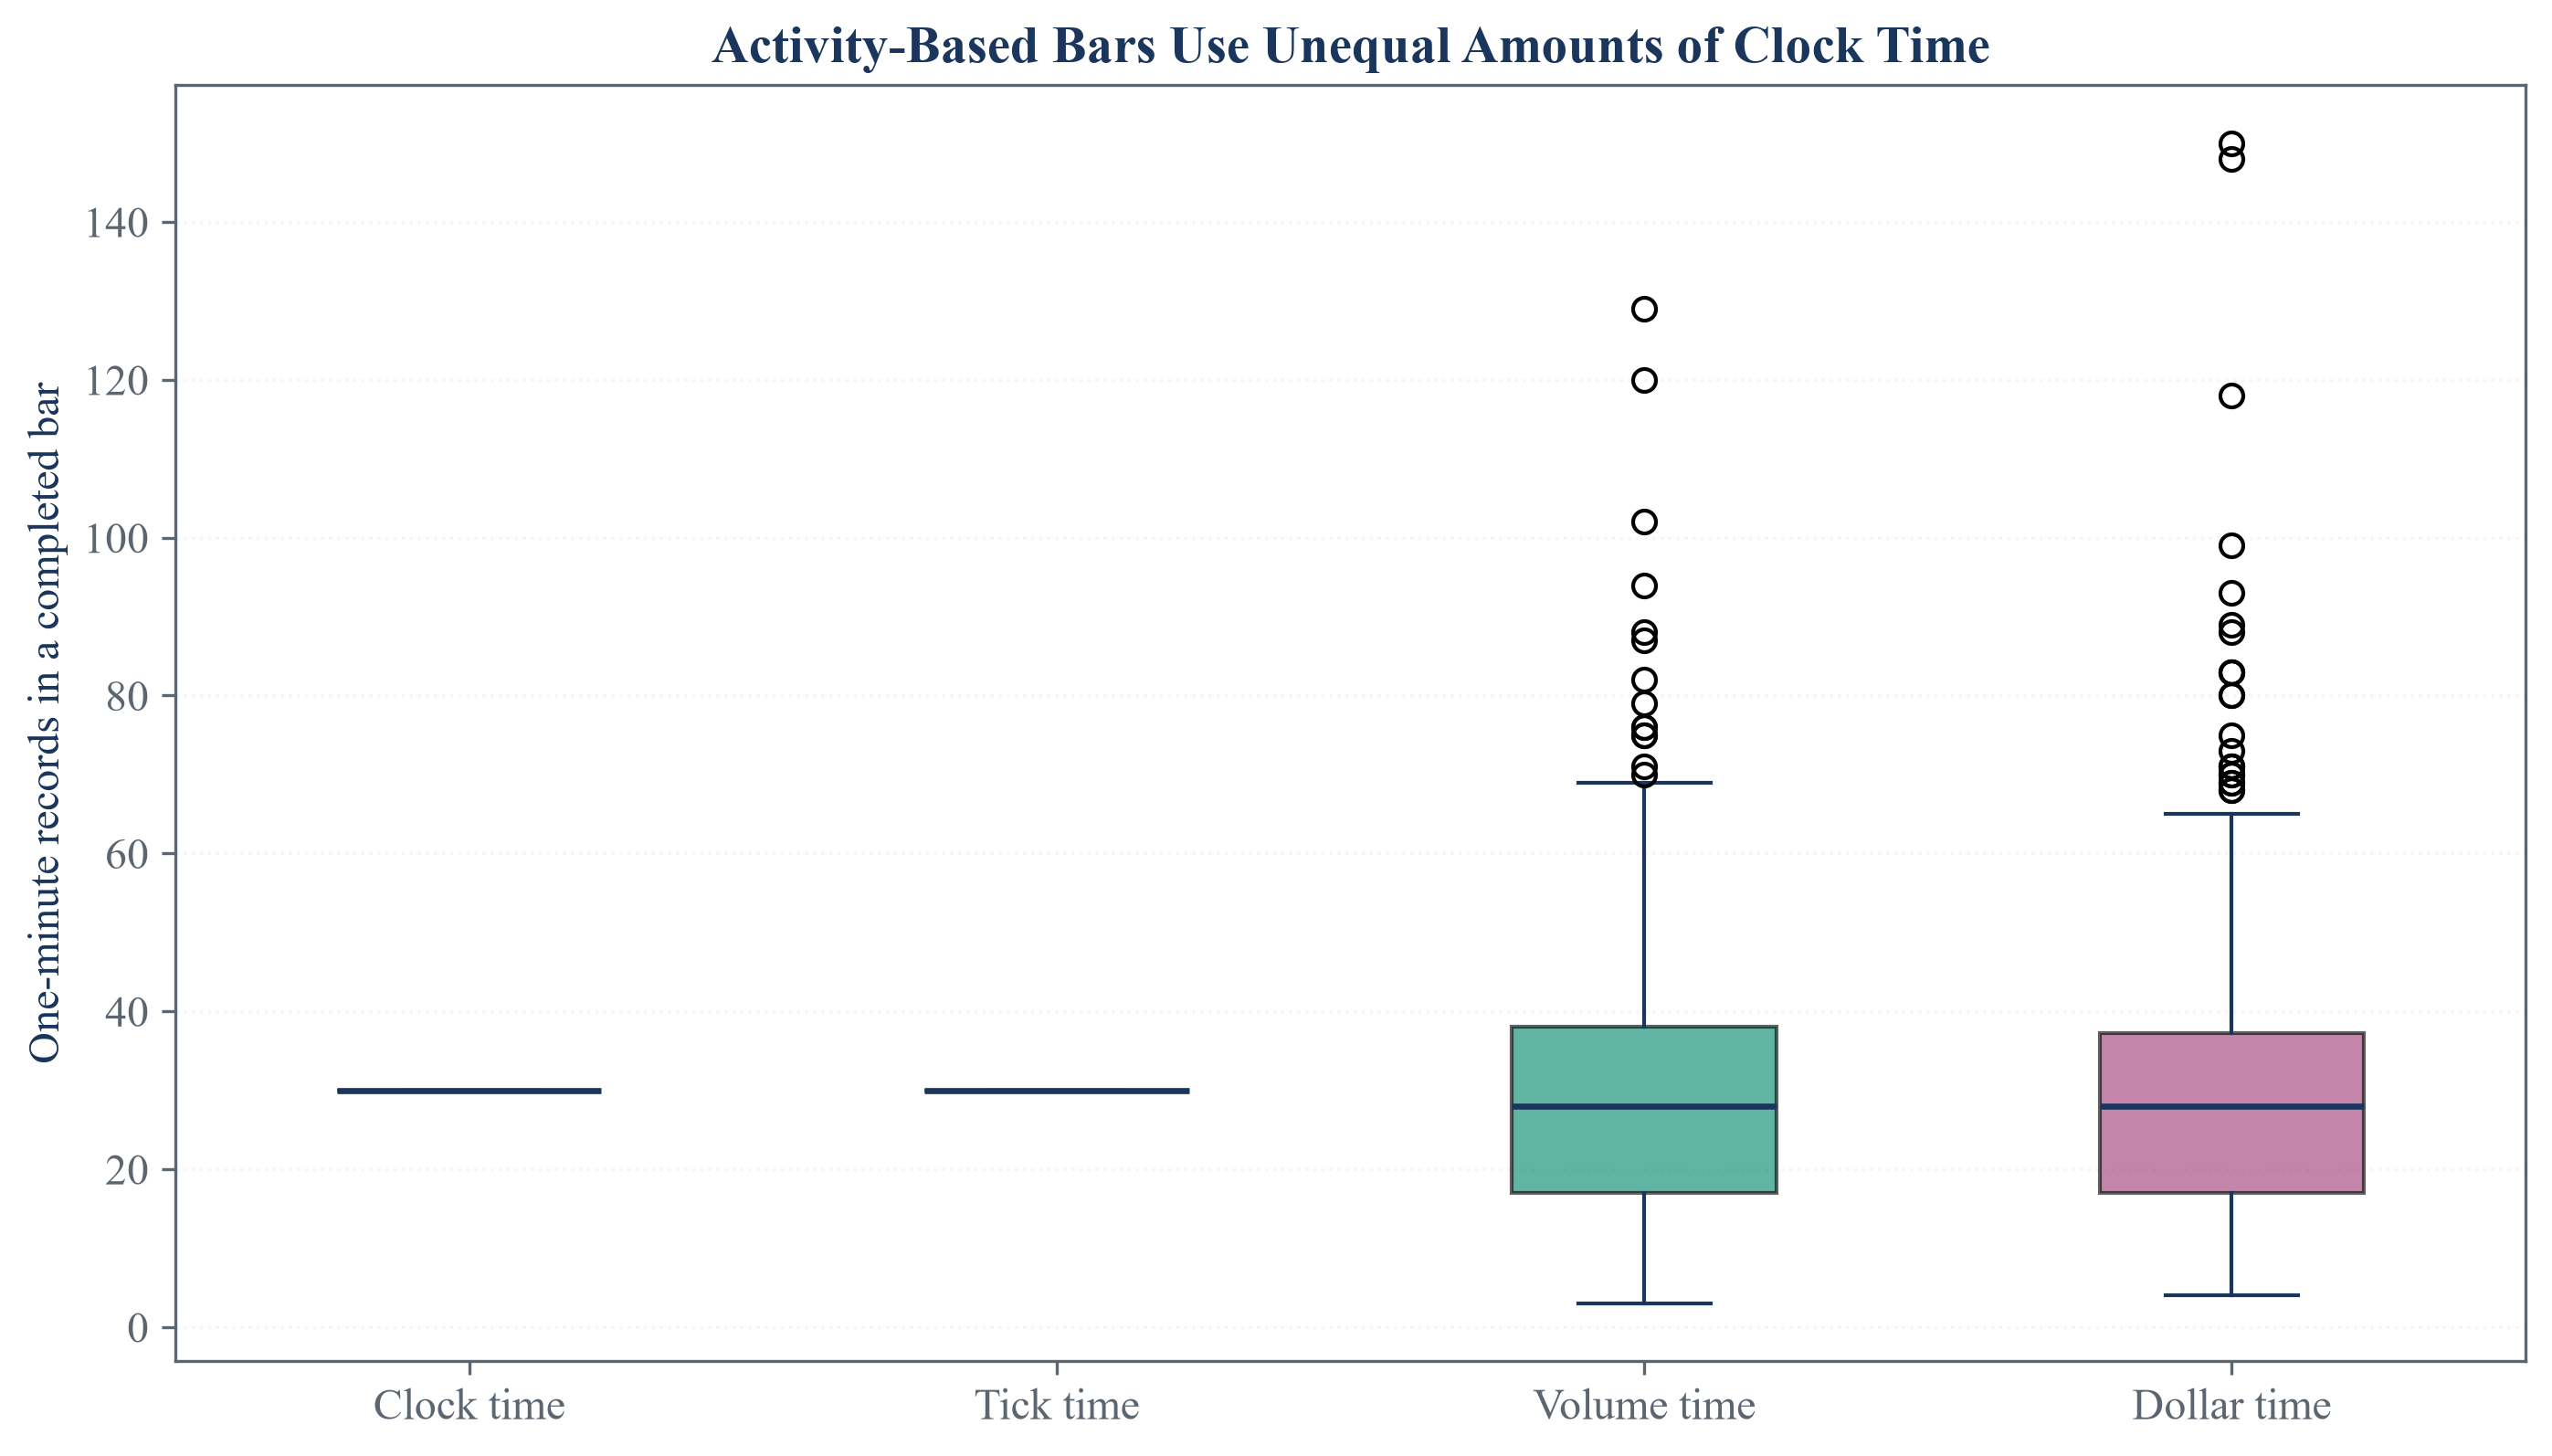

In [5]:
dispersion_rows = []
for name, frame in bars.items():
    counts = frame["Records"].to_numpy(dtype=float)
    dispersion_rows.append({
        "Measure of progress": name,
        "Smallest record count": counts.min(),
        "Middle record count": np.median(counts),
        "Largest record count": counts.max(),
        "Standard deviation divided by mean": counts.std(ddof=1) / counts.mean(),
    })
standard_bar_dispersion = pd.DataFrame(dispersion_rows)
save_table(standard_bar_dispersion, "standard_bar_dispersion", "Variation in the number of one-minute records contained in each completed bar.", "tab:standard-bar-dispersion")
display(standard_bar_dispersion.round(4))

figure, axis = plt.subplots(figsize=(9.2, 5.2), constrained_layout=True)
samples = [bars[name]["Records"].to_numpy() for name in bars]
box = axis.boxplot(samples, tick_labels=list(bars), patch_artist=True, showfliers=True, medianprops={"color": palette["text"], "linewidth": 1.6})
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.62)
for element in ["whiskers", "caps", "fliers"]:
    for artist in box[element]:
        artist.set_color(palette["text"])
axis.set_ylabel("One-minute records in a completed bar")
axis.set_title("Activity-Based Bars Use Unequal Amounts of Clock Time")
axis.grid(True, axis="y", alpha=0.30)
figure.savefig(FIGURES / "records_per_bar.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "records_per_bar.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "records_per_bar.png")))
plt.close(figure)

## Tests

In [6]:
assert len(raw) == 10080
assert raw["time"].is_monotonic_increasing
assert raw[["close", "volume"]].notna().all().all()
assert (raw["close"] > 0.0).all()
assert (raw["volume"] >= 0.0).all()
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(bars["Clock time"]) == 335
assert len(bars["Tick time"]) == 336
assert len(bars["Volume time"]) == 325
assert len(bars["Dollar time"]) == 324
assert np.all(bars["Tick time"]["Records"] == 30)
assert np.all(bars["Volume time"]["Volume"] >= volume_level)
assert np.all(bars["Dollar time"]["Dollar value"] >= dollar_level)
volume_closing_records = bars["Volume time"]["Last record"].astype(int).to_numpy() - 1
dollar_closing_records = bars["Dollar time"]["Last record"].astype(int).to_numpy() - 1
assert np.all(bars["Volume time"]["Volume"].to_numpy() - volume_level < raw.loc[volume_closing_records, "volume"].to_numpy() + 1e-12)
assert np.all(bars["Dollar time"]["Dollar value"].to_numpy() - dollar_level < (raw.loc[dollar_closing_records, "close"] * raw.loc[dollar_closing_records, "volume"]).to_numpy() + 1e-8)
assert standard_bar_summary["Complete bars"].gt(300).all()
assert standard_bar_dispersion.loc[standard_bar_dispersion["Measure of progress"] == "Tick time", "Standard deviation divided by mean"].iloc[0] == 0.0
assert standard_bar_dispersion.loc[standard_bar_dispersion["Measure of progress"] == "Volume time", "Standard deviation divided by mean"].iloc[0] > 0.0
assert standard_bar_dispersion.loc[standard_bar_dispersion["Measure of progress"] == "Dollar time", "Standard deviation divided by mean"].iloc[0] > 0.0
assert (FIGURES / "four_financial_clocks.pdf").exists()
assert (FIGURES / "records_per_bar.pdf").exists()
assert (TABLES / "data_provenance.tex").exists()
assert (TABLES / "standard_bar_summary.tex").exists()
assert (TABLES / "standard_bar_dispersion.tex").exists()